# Gold Audit 5: Anomalies of `gld_player_gaming_daily`

**Goal:** understand two anomalies of notebook 04: **`play_secs` over 24 h** and **negative `won_real_eur`**. Who has them (how many players, always the same ones?), where (brand, provider, game, currency, hour, day) and what the values look like (repeated values, relation with the other columns).

**Only aggregates:** no player id leaves DuckDB. "Who" is answered with concentration (share of the top 1, 10 and 100 players) and repetition (days with an anomaly per player).

**Lift:** share of the anomalous rows in a group divided by the share of all rows in that group. Lift 5 = the group has 5 times more anomalies than its size; lift around 1 = no pattern.

In [8]:
%reload_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RUN_S3 = True    # True the first time: reads S3 (needs `aws sso login`) and fills cache/
os.environ["RUN_S3"] = "1" if RUN_S3 else "0"

sys.path.insert(0, str(Path.cwd()))
import gaming

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
cfg = gaming.load_config()
GROUPS = ["brand_id", "provider_code", "game_id", "currency", "source_system", "dq_status", "hour(first_played_at)", "event_date"]


def profile(cfg, cond, groups=GROUPS):
    """Concentration, then the top values of each group with their lift."""
    display(gaming.anomaly_players(cfg, cond).style.format(precision=1).hide(axis="index"))
    for col in groups:
        t = gaming.anomaly_by(cfg, cond, col, top=50 if col.startswith(("hour", "event_date")) else 15)
        print(col)
        display(t[["value", "rows", "bad_rows", "bad_pct", "share_of_bad", "share_of_rows", "lift", "bad_players"]]
                .style.format(precision=2).hide(axis="index").background_gradient(subset=["lift"], cmap="Reds"))

## 1. `play_secs` over 24 h (September 2026)

A row is one player, one game and one day, so `play_secs` can never be over 86,400.

In [9]:
PLAY = "play_secs > 86400"
profile(cfg, PLAY)

players,bad_rows,top1_pct,top10_pct,top100_pct,players_1_day,players_2_5_days,players_6_15_days,players_over_15_days
7475,18401.0,0.5,2.5,13.4,4723.0,2145.0,510.0,97.0


brand_id


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
73,662054,8891.00,1.34,48.32,27.05,1.79,3233
23,916073,6101.00,0.67,33.16,37.42,0.89,2374
14,240492,1550.00,0.64,8.42,9.82,0.86,642
72,343373,1107.00,0.32,6.02,14.03,0.43,712
64,285944,752.00,0.26,4.09,11.68,0.35,514


provider_code


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
58,131722,12506.00,9.49,67.96,5.38,12.63,3859
62,1233549,2144.00,0.17,11.65,50.39,0.23,1620
46,178618,1725.00,0.97,9.37,7.30,1.28,1267
50,22179,634.00,2.86,3.45,0.91,3.80,305
69,36456,407.00,1.12,2.21,1.49,1.49,346
37,12271,386.00,3.15,2.10,0.50,4.18,335
75,118796,111.00,0.09,0.60,4.85,0.12,94
81,36535,85.00,0.23,0.46,1.49,0.31,81
61,18624,66.00,0.35,0.36,0.76,0.47,51
83,784,62.00,7.91,0.34,0.03,10.52,41


...

value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
ok,2446959,18384.00,0.75,99.91,99.96,1.00,7465
fx_suspect,977,17.00,1.74,0.09,0.04,2.31,14


hour(first_played_at)


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
0,120813,1675.00,1.39,9.10,4.94,1.84,1011
9,98093,1121.00,1.14,6.09,4.01,1.52,846
10,103752,1071.00,1.03,5.82,4.24,1.37,820
11,105833,1011.00,0.96,5.49,4.32,1.27,808
8,85436,995.00,1.16,5.41,3.49,1.55,731
7,76418,966.00,1.26,5.25,3.12,1.68,746
15,120951,940.00,0.78,5.11,4.94,1.03,774
12,110208,940.00,0.85,5.11,4.50,1.13,786
13,113841,936.00,0.82,5.09,4.65,1.09,785
16,127166,886.00,0.70,4.81,5.19,0.93,724


event_date


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
2026-09-08,81872,947.00,1.16,5.15,3.34,1.54,894
2026-09-04,83565,836.00,1.00,4.54,3.41,1.33,789
2026-09-19,85383,785.00,0.92,4.27,3.49,1.22,718
2026-09-05,84557,781.00,0.92,4.24,3.45,1.23,718
2026-09-09,83690,779.00,0.93,4.23,3.42,1.24,723
2026-09-12,84859,759.00,0.89,4.12,3.47,1.19,719
2026-09-11,90201,752.00,0.83,4.09,3.68,1.11,704
2026-09-18,86450,744.00,0.86,4.04,3.53,1.14,658
2026-09-03,76055,693.00,0.91,3.77,3.11,1.21,647
2026-09-10,86927,683.00,0.79,3.71,3.55,1.05,647


**Hour and day:** if the anomalies follow the hours of play (more at night, like all rows), it is a calculation error; if they pile up at one hour or on some days, it is a process or a release.

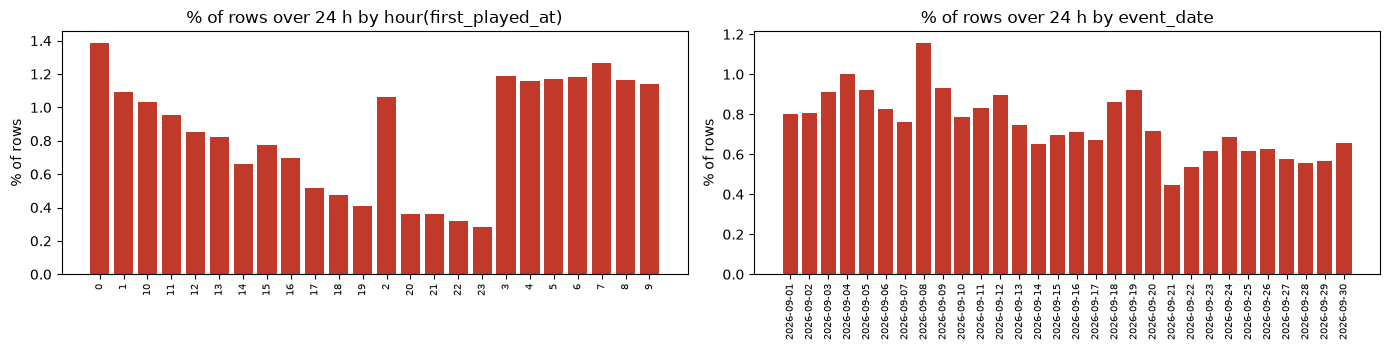

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, col in zip(axes, ["hour(first_played_at)", "event_date"]):
    t = gaming.anomaly_by(cfg, PLAY, col, top=50).sort_values("value")
    ax.bar(t["value"].astype(str), t["bad_pct"], color="#c0392b")
    ax.set(title=f"% of rows over 24 h by {col}", ylabel="% of rows")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout(); plt.show()

**What the values look like.** Against the normal rows:
- `span_secs`: time between the first and the last play of the row;
- `play_over_span`: `play_secs` / `span_secs` (over 1 = more play than time passed);
- `secs_per_bet`: seconds of play per bet (a few seconds is normal);
- `days`: `play_secs` in days.

Then the most frequent values: repeated values point to a default or a session that never closes.

In [11]:
PLAY_EXPR = {"play_secs": "play_secs", "days": "play_secs / 86400",
             "span_secs": "epoch(last_played_at) - epoch(first_played_at)",
             "play_over_span": "play_secs / NULLIF(epoch(last_played_at) - epoch(first_played_at), 0)",
             "secs_per_bet": "play_secs / NULLIF(bets, 0)", "bets": "bets", "rounds": "rounds", "turnover_eur": "turnover_eur"}
display(gaming.anomaly_quantiles(cfg, PLAY, PLAY_EXPR).style.format("{:,.1f}"))
display(gaming.anomaly_values(cfg, PLAY, "round(play_secs / 86400)").rename(columns={"value": "days (rounded)"}))
display(gaming.anomaly_values(cfg, PLAY, "play_secs").rename(columns={"value": "play_secs (exact)"}))

,days (rounded),rows,players
0,1.0,8095,4693
1,2.0,5119,2967
2,3.0,2059,1418
3,4.0,1060,815
4,5.0,677,557
5,6.0,499,435
6,7.0,286,240
7,8.0,131,107
8,9.0,73,65
9,10.0,67,56


,play_secs (exact),rows,players
0,522210.753,3,3
1,608219.910,3,3
2,612847.226,3,3
3,596851.410,3,3
4,562385.730,2,2
5,429389.990,2,2
6,538135.974,2,2
7,519839.897,2,2
8,419879.874,2,2
9,140362.979,2,2


## 2. Negative `won_real_eur` (history)

A win is never negative. The file metadata shows a negative minimum on 155 days, but it covers every operator. Here I read only those days and only our five brands.

In [12]:
ext = gaming.daily_extremes(["won_real_eur"])
neg_days = ext.index[ext["won_real_eur:min_num"] < 0].date.tolist()
won_cfg = {**cfg, "period": {"start": min(neg_days), "end": max(neg_days)}, "days": neg_days}
WON = "won_real_eur < 0"
by_brand = gaming.anomaly_by(won_cfg, WON, "brand_id")
print(f"{len(neg_days)} days with a negative minimum (all operators); "
      f"{int(by_brand['bad_rows'].sum()):,} negative rows in our brands, of {int(by_brand['rows'].sum()):,}")

155 days with a negative minimum (all operators); 309 negative rows in our brands, of 14,470,660


If there are negative rows in our brands: the same profile, and what the value is next to the stake. `won_over_stake` = -1 means the player gets back minus the stake (a rollback written as a negative win); a value that matches another column points to a sign or a column error.

In [13]:
if by_brand["bad_rows"].sum():
    profile(won_cfg, WON, ["brand_id", "provider_code", "game_id", "currency", "source_system", "dq_status", "event_date"])
    WON_EXPR = {"won_real_eur": "won_real_eur", "wagered_real_eur": "wagered_real_eur",
                "won_over_stake": "won_real_eur / NULLIF(wagered_real_eur, 0)",
                "payout_eur": "payout_eur", "bets": "bets", "rounds": "rounds", "winning_rounds": "winning_rounds"}
    display(gaming.anomaly_quantiles(won_cfg, WON, WON_EXPR).style.format("{:,.2f}"))
    display(gaming.anomaly_values(won_cfg, WON, "round(won_real_eur / NULLIF(wagered_real_eur, 0), 2)")
            .rename(columns={"value": "won / stake"}))
    display(gaming.anomaly_values(won_cfg, WON, "round(won_real_eur, 2)").rename(columns={"value": "won_real_eur"}))
else:
    print("No negative win in our five brands: the negative minimums of the metadata are from other operators.")

players,bad_rows,top1_pct,top10_pct,top100_pct,players_1_day,players_2_5_days,players_6_15_days,players_over_15_days
295,309.0,0.6,6.5,36.9,282.0,13.0,0.0,0.0


brand_id


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
23,5294094,126.00,0.00,40.78,36.59,1.11,117
73,4564705,96.00,0.00,31.07,31.54,0.98,94
14,1260632,37.00,0.00,11.97,8.71,1.37,36
64,2001000,34.00,0.00,11.00,13.83,0.80,32
72,1350229,16.00,0.00,5.18,9.33,0.55,16


provider_code


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
58,622175,259.00,0.04,83.82,4.30,19.49,247
50,95292,50.00,0.05,16.18,0.66,24.57,48
65,102822,0.00,0.00,0.00,0.71,0.00,0
75,661523,0.00,0.00,0.00,4.57,0.00,0
46,893859,0.00,0.00,0.00,6.18,0.00,0
74,134446,0.00,0.00,0.00,0.93,0.00,0
48,367566,0.00,0.00,0.00,2.54,0.00,0
86,9914,0.00,0.00,0.00,0.07,0.00,0
69,247578,0.00,0.00,0.00,1.71,0.00,0
76,45163,0.00,0.00,0.00,0.31,0.00,0


...

value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
ok,14470578,309.00,0.00,100.00,100.00,1.00,295
fx_suspect,82,0.00,0.00,0.00,0.00,0.00,0


event_date


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
2025-05-05,106773,17.00,0.02,5.50,0.74,7.46,17
2025-04-26,107195,13.00,0.01,4.21,0.74,5.68,13
2025-05-22,97559,7.00,0.01,2.27,0.67,3.36,7
2025-05-08,99113,7.00,0.01,2.27,0.68,3.31,7
2025-04-01,114446,6.00,0.01,1.94,0.79,2.46,6
2025-04-17,94515,6.00,0.01,1.94,0.65,2.97,6
2025-04-13,95264,6.00,0.01,1.94,0.66,2.95,6
2025-04-22,94649,6.00,0.01,1.94,0.65,2.97,6
2025-09-16,101382,6.00,0.01,1.94,0.70,2.77,6
2025-09-09,98331,6.00,0.01,1.94,0.68,2.86,6


,won / stake,rows,players
0,NaN,60,60
1,-0.01,9,9
2,-0.00,7,7
3,-0.05,5,5
4,-0.22,5,5
5,-0.11,4,4
6,-0.08,4,4
7,-0.17,3,3
8,-0.36,3,3
9,-0.16,3,3


,won_real_eur,rows,players
0,-0.02,6,6
1,-0.00,3,3
2,-0.01,2,2
3,-0.09,2,2
4,-2.51,2,2
5,-0.16,2,2
6,-10.35,2,2
7,-3.44,1,1
8,-4.26,1,1
9,-2.98,1,1


**Last play on a later day than `event_date`.** If `last_played_at` is the time a sports bet is settled, providers 58 and 50 should have a high lift.

In [14]:
profile(cfg, "CAST(last_played_at AS DATE) > event_date", ["provider_code", "game_id"])


players,bad_rows,top1_pct,top10_pct,top100_pct,players_1_day,players_2_5_days,players_6_15_days,players_over_15_days
16498,40335.0,0.4,1.5,7.0,9759.0,5437.0,1192.0,110.0


provider_code


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
58,131722,18782.00,14.26,46.57,5.38,8.65,5762
62,1233549,12854.00,1.04,31.87,50.39,0.63,7583
46,178618,2633.00,1.47,6.53,7.30,0.89,1741
50,22179,1293.00,5.83,3.21,0.91,3.54,599
69,36456,710.00,1.95,1.76,1.49,1.18,558
85,190383,696.00,0.37,1.73,7.78,0.22,518
75,118796,656.00,0.55,1.63,4.85,0.34,503
72,135436,486.00,0.36,1.20,5.53,0.22,425
37,12271,456.00,3.72,1.13,0.50,2.26,384
81,36535,259.00,0.71,0.64,1.49,0.43,216


game_id


value,rows,bad_rows,bad_pct,share_of_bad,share_of_rows,lift,bad_players
Combo,69667,12574.00,18.05,31.17,2.85,10.95,4201
Single,60306,5784.00,9.59,14.34,2.46,5.82,2807
vs20olympx,102092,1556.00,1.52,3.86,4.17,0.92,1245
vs20olympgold,78535,1431.00,1.82,3.55,3.21,1.11,1065
vs20fruitswx,75008,1188.00,1.58,2.95,3.06,0.96,944
1,8876,825.00,9.29,2.05,0.36,5.64,436
vs20olympgate,46835,738.00,1.58,1.83,1.91,0.96,573
vs20sugarrushx,42779,706.00,1.65,1.75,1.75,1.00,567
vs20fruitsw,45139,676.00,1.50,1.68,1.84,0.91,521
vs20starlightx,35005,427.00,1.22,1.06,1.43,0.74,368


## Casino or sportsbook

The gaming table has no product column, but the game catalogue (`gld_game_profile`) has `vertical` and `game_type`. Rows, players and anomalies per vertical, joining on tenant and `game_id`. If `verticals_per_game` is above 1, a `game_id` has two verticals and the join is not safe.

In [15]:
v = gaming.game_verticals(cfg)
v = v.assign(rows_pct=100 * v["rows"] / v["rows"].sum(), play_over_day_pct=100 * v["play_over_day"] / v["rows"])
display(v.style.format(precision=2).hide(axis="index"))
display(v.groupby("vertical")[["rows", "players", "play_over_day", "negative_wins", "turnover_eur"]].sum().sort_values("rows", ascending=False))

vertical,game_type,verticals_per_game,rows,players,games,play_over_day,negative_wins,turnover_eur,rows_pct,play_over_day_pct
,,1,2446294,101655,11537,18390.00,3.00,626095480.95,99.93,0.75
(not in catalogue),,,1642,721,34,11.00,0.00,114249.42,0.07,0.67


,rows,players,play_over_day,negative_wins,turnover_eur
vertical,,,,,
,2446294,101655,18390.0,3.0,6.260955e+08
(not in catalogue),1642,721,11.0,0.0,1.142494e+05


**Providers 58 and 50.** Per `game_id`, the % of its rows from these two providers: if only bet types reach 100%, the provider separates sports betting from casino.

In [16]:
display(gaming.anomaly_by(cfg, "provider_code IN (58, 50)", "game_id", top=40)
        [["value", "rows", "bad_rows", "bad_pct"]])


,value,rows,bad_rows,bad_pct
0,Combo,69667,69667.0,100.000000
1,Single,60306,60306.0,100.000000
2,2,10035,10014.0,99.790732
3,1,8876,8795.0,99.087427
4,3,3474,3370.0,97.006333
5,System,1749,1749.0,100.000000
6,78162,8,0.0,0.000000
7,pp_ultra_disco,4,0.0,0.000000
8,56410,1,0.0,0.000000
9,ea_cyber_race,3,0.0,0.000000


In [17]:
display(gaming.anomaly_by(cfg, "play_secs > 86400", "provider_code IN (58, 50)"))


,value,rows,bad_rows,players,bad_players,bad_pct,share_of_bad,share_of_rows,lift
0,true,153901,13140.0,20086,4164,8.537956,71.409163,6.28697,11.358280
1,false,2294035,5261.0,95084,3587,0.229334,28.590837,93.71303,0.305089


## 3. Findings

### `play_secs` over 24 h (September 2026: 18,401 rows, 7,475 players)

- **It is mainly sports betting.** Provider 58 has 68% of the anomalies with 5% of the rows (lift 12.6), and the games with most anomalies are bet types, not casino games: `Combo` (lift 17.6), `Single` (6.6), `System` (21.8), `1`, `2`, `3`. Providers 58 and 50 together have 71% of the anomalies.
- **Why:** a sports bet stays open until the match ends, so `play_secs` measures how long the bet is open, not time of play. The anomalous rows have few bets (median 9 against 51) and a median of 19,000 seconds per bet (1.4 s in normal rows). Several open bets at the same time are added up (`play_secs` / span: median 1.2).
- **Not a few players:** the top 10 players have 2.5% of the anomalies and the top 100 13.4%; 4,723 of the 7,475 players have it on one day only.
- **Not a process error:** every day has anomalies (0.45% to 1.16% of the rows) and there is no repeated value (no value appears more than 3 times), so it is not a default value or a bad load.
- **Brand 73 and EUR** have more anomalies (lift 1.8 and 3.1) because they have more sports betting.
- **Casino:** the other 29% (about 5,300 rows, 0.2% of the casino rows) is still over 24 h, for example the slots of provider 62 (2,144 rows). There the cause is games played at the same time.

### Negative `won_real_eur` (155 days: 309 rows in our brands, of 14.5 million)

- **Only sports betting:** 100% of the rows are from providers 58 (84%) and 50 (16%), in bet types (`Single`, `Combo`, `System`, `1`, `2`, `3`).
- **They look like corrections of a win paid before:** in 60 rows there is no stake on that day, every row has at least one winning round, and the values are small (median −17.56 €, 1% below −2,112 €). A bet that is settled again (a result that changes, a cancelled cash-out) takes back the win on the day of the correction.
- **Spread out:** 295 players, 282 of them on one day only; most in April to September 2025, very few after. **Three rows in September 2026.**
- **The −263,000 € of the metadata is from another operator:** in our brands the minimum is around −2,000 €.

### `last_played_at` on a later day (40,335 rows, 1.6%, 16,498 players)

- **Not an error.** Half are sports bets settled on a later day (providers 58 and 50, lift 8.7 and 3.5; `Combo` lift 11, `System` 14.7). The other half is casino play that goes past midnight (provider 62, lift 0.63, about 1% to 2% of the rows of each game): the row is the day of the first play.

### Casino or sportsbook

- **The game catalogue cannot separate them yet:** 99.93% of the rows join `gld_game_profile` (one vertical per `game_id`), but `vertical` and `game_type` are empty for every game. The workbook defines them; the lake table does not fill them.
- **The provider can separate them:** providers 58 and 50 have only six `game_id`: `Combo`, `Single`, `System`, `1`, `2` and `3` (153,901 rows, 6.3% of the rows). No casino game comes from them. The ids `1`, `2` and `3` also exist in casino providers (about 200 rows), so the rule must use the provider, not the `game_id`: **sports betting = `provider_code IN (58, 50)`**.
